In [16]:
import pandas as pd
import os
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [9]:
print(os.getcwd())

/Users/danielpearce/Python/workout_app


In [8]:
os.chdir('/Users/danielpearce/Python/workout_app')

In [11]:
df = pd.read_csv(r'data/workout_data.csv')

In [12]:
df.head()

,title,start_time,end_time,description,exercise_title,superset_id,exercise_notes,set_index,set_type,weight_kg,reps,distance_km,duration_seconds,rpe
0,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,0,normal,30.0,12.0,NaN,NaN,NaN
1,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,1,normal,35.0,12.0,NaN,NaN,NaN
2,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,2,normal,40.0,12.0,NaN,NaN,NaN
3,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Overhead Triceps Extension (Cable),NaN,NaN,0,normal,28.0,12.0,NaN,NaN,NaN
4,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Overhead Triceps Extension (Cable),NaN,NaN,1,normal,31.5,12.0,NaN,NaN,NaN


In [15]:
df['title'].nunique()

141

In [22]:
# Deduplicate: one workout = unique title + day
df["date"] = pd.to_datetime(df["start_time"]).dt.date
workouts = df.drop_duplicates(subset=["title", "date"]).copy()

In [18]:
df.head()

,title,start_time,end_time,description,exercise_title,superset_id,exercise_notes,set_index,set_type,weight_kg,reps,distance_km,duration_seconds,rpe,date
0,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,0,normal,30.0,12.0,NaN,NaN,NaN,2026-03-09
1,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,1,normal,35.0,12.0,NaN,NaN,NaN,2026-03-09
2,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,2,normal,40.0,12.0,NaN,NaN,NaN,2026-03-09
3,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Overhead Triceps Extension (Cable),NaN,NaN,0,normal,28.0,12.0,NaN,NaN,NaN,2026-03-09
4,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Overhead Triceps Extension (Cable),NaN,NaN,1,normal,31.5,12.0,NaN,NaN,NaN,2026-03-09


In [20]:
workouts.head()

,title,start_time,end_time,description,exercise_title,superset_id,exercise_notes,set_index,set_type,weight_kg,reps,distance_km,duration_seconds,rpe,date
0,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,0,normal,30.0,12.0,NaN,NaN,NaN,2026-03-09
15,Lower new gym,"6 Mar 2026, 19:50","6 Mar 2026, 20:28",NaN,Pendulum Squat (Machine),NaN,NaN,0,normal,60.0,12.0,NaN,NaN,NaN,2026-03-06
24,Accessories and Core,"4 Mar 2026, 18:51","4 Mar 2026, 20:06",NaN,Ab Wheel,NaN,NaN,0,normal,NaN,12.0,NaN,NaN,NaN,2026-03-04
37,Upper Body Strength,"3 Mar 2026, 20:27","3 Mar 2026, 21:28",NaN,Bench Press (Dumbbell),NaN,NaN,0,normal,55.0,10.0,NaN,NaN,NaN,2026-03-03
52,Lower Body Strength,"27 Feb 2026, 14:12","27 Feb 2026, 14:56",NaN,Squat (Barbell),NaN,NaN,0,normal,20.0,12.0,NaN,NaN,NaN,2026-02-27


In [23]:
# Group by week
workouts["week"] = pd.to_datetime(workouts["date"]) - pd.to_timedelta(
    pd.to_datetime(workouts["date"]).dt.day_of_week, unit="d"
)

In [24]:
workouts.head()

,title,start_time,end_time,description,exercise_title,superset_id,exercise_notes,set_index,set_type,weight_kg,reps,distance_km,duration_seconds,rpe,date,week
0,Popping Pseudo to get through the workout,"9 Mar 2026, 19:17","9 Mar 2026, 20:09",NaN,Bicep Curl (Barbell),NaN,NaN,0,normal,30.0,12.0,NaN,NaN,NaN,2026-03-09,2026-03-09
15,Lower new gym,"6 Mar 2026, 19:50","6 Mar 2026, 20:28",NaN,Pendulum Squat (Machine),NaN,NaN,0,normal,60.0,12.0,NaN,NaN,NaN,2026-03-06,2026-03-02
24,Accessories and Core,"4 Mar 2026, 18:51","4 Mar 2026, 20:06",NaN,Ab Wheel,NaN,NaN,0,normal,NaN,12.0,NaN,NaN,NaN,2026-03-04,2026-03-02
37,Upper Body Strength,"3 Mar 2026, 20:27","3 Mar 2026, 21:28",NaN,Bench Press (Dumbbell),NaN,NaN,0,normal,55.0,10.0,NaN,NaN,NaN,2026-03-03,2026-03-02
52,Lower Body Strength,"27 Feb 2026, 14:12","27 Feb 2026, 14:56",NaN,Squat (Barbell),NaN,NaN,0,normal,20.0,12.0,NaN,NaN,NaN,2026-02-27,2026-02-23


In [25]:
weekly = workouts.groupby("week").size().reset_index(name="Workout_count")
weekly = weekly.sort_values("week")

In [26]:
weekly.head()

,week,Workout_count
0,2025-03-31,2
1,2025-04-07,4
2,2025-04-21,4
3,2025-04-28,4
4,2025-05-05,4


In [27]:
all_weeks = pd.date_range(weekly["week"].min(), weekly["week"].max(), freq="W-MON")
weekly = weekly.set_index("week").reindex(all_weeks, fill_value=0).reset_index()
weekly.columns = ["week", "workout_count"]

In [28]:
weekly.head()

,week,workout_count
0,2025-03-31,2
1,2025-04-07,4
2,2025-04-14,0
3,2025-04-21,4
4,2025-04-28,4


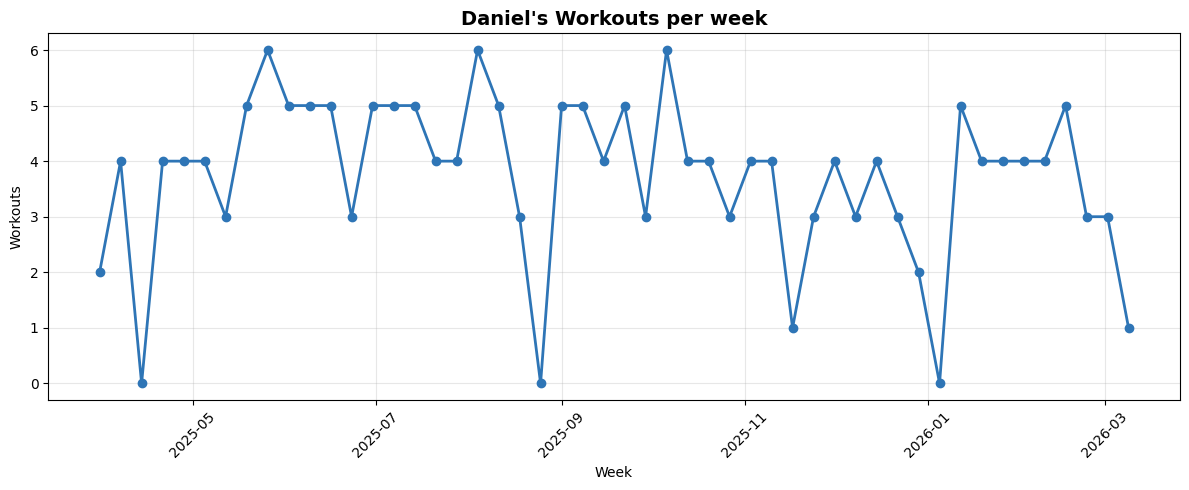

In [29]:
#Plot
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(weekly["week"], weekly["workout_count"], marker="o", linewidth=2, color="#2E75B6")
ax.set_title("Daniel's Workouts per week", fontsize=14, fontweight="bold")
ax.set_xlabel("Week")
ax.set_ylabel("Workouts")
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
weekly.head()

,week,workout_count
0,2025-03-31,2
1,2025-04-07,4
2,2025-04-14,0
3,2025-04-21,4
4,2025-04-28,4


In [34]:
weekly["workout_count"].mean()

np.float64(3.74)